# House Price Prediction — Classical Machine Learning
## Project 01: Linear Regression from Scratch Workflow

Welcome to our first Machine Learning project! In this notebook, we follow an end-to-end ML lifecycle:
1. **Phase 1**: Environment & Library Setup
2. **Phase 2**: Understand, explore, clean, and visualize housing data
3. **Phase 3**: Build and train a Scikit-Learn Linear Regression model
4. **Phase 4**: Evaluate performance using MAE, MSE, RMSE, and $R^2$ score
5. **Phase 5**: Serialize and persist the trained model using Joblib for production inference

### Phase 1 — Import Libraries
We import NumPy for numerical operations, Pandas for dataframe processing, Matplotlib for data visualization, and Scikit-Learn for model building and evaluation.

In [3]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("All ML libraries imported successfully!")

All ML libraries imported successfully!


### Phase 2 — Understand and Prepare Data
Now we load the house prices dataset from `../data/house_prices.csv` using Pandas.

In [4]:
# Define dataset path
data_path = Path('../data/house_prices.csv')
df = pd.read_csv(data_path)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("First 5 Rows:")
df.head()

Dataset Shape: 61 rows, 5 columns

First 5 Rows:


,area,bedrooms,bathrooms,age,price
0,550,1,1.0,12.0,135000
1,620,1,1.0,8.0,148000
2,700,1,1.0,15.0,152000
3,750,2,1.0,20.0,160000
4,800,2,1.0,NaN,175000


In [5]:
# Dataset structural information
print("Dataset Summary Information:")
df.info()

print("\nDescriptive Statistics:")
df.describe()

Dataset Summary Information:
<class 'pandas.DataFrame'>
RangeIndex: 61 entries, 0 to 60
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   area       61 non-null     int64  
 1   bedrooms   61 non-null     int64  
 2   bathrooms  61 non-null     float64
 3   age        57 non-null     float64
 4   price      61 non-null     int64  
dtypes: float64(2), int64(3)
memory usage: 2.5 KB

Descriptive Statistics:


,area,bedrooms,bathrooms,age,price
count,61.000000,61.000000,61.000000,57.000000,61.000000
mean,2169.180328,3.934426,2.926230,10.473684,442327.868852
std,1007.293891,1.314900,1.139576,4.968132,199901.785994
min,550.000000,1.000000,1.000000,2.000000,135000.000000
25%,1350.000000,3.000000,2.000000,7.000000,278000.000000
50%,2100.000000,4.000000,3.000000,10.000000,425000.000000
75%,2850.000000,5.000000,4.000000,14.000000,585000.000000
max,4500.000000,6.000000,5.000000,22.000000,895000.000000


#### Handling Missing Values
Real-world data often has null or missing entries. Let's inspect and impute missing values.

In [6]:
# Check missing values per column
print("Missing values per feature:")
print(df.isnull().sum())

# Impute missing values with column medians
for col in df.columns:
    if df[col].isnull().sum() > 0:
        median_val = df[col].median()
        df[col] = df[col].fillna(median_val)
        print(f"Imputed missing values in '{col}' with median: {median_val}")

print("\nRemaining missing values:", df.isnull().sum().sum())

Missing values per feature:
area         0
bedrooms     0
bathrooms    0
age          4
price        0
dtype: int64
Imputed missing values in 'age' with median: 10.0

Remaining missing values: 0


#### Data Visualization — Relationship between Area and Price
Let's create a scatter plot of House Area (sq ft) vs House Price ($) to inspect the linear correlation.

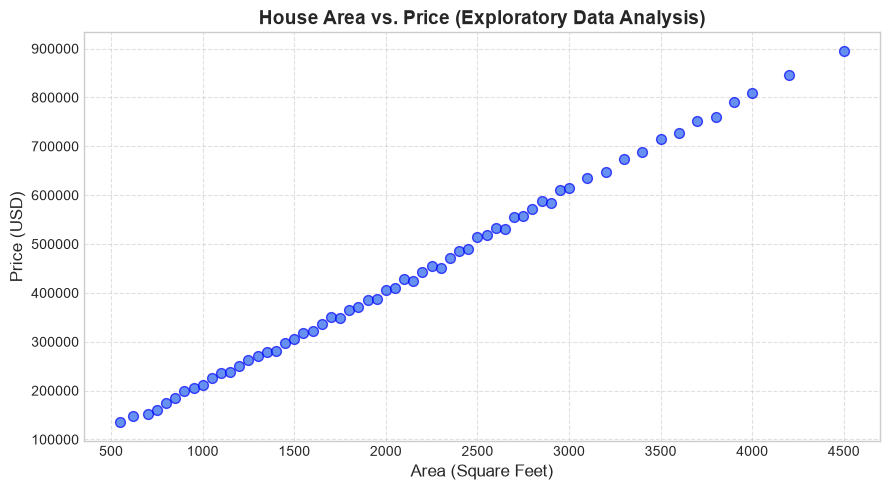

Pearson Correlation between Area and Price: 0.9994 (Strong positive correlation!)


In [7]:
plt.figure(figsize=(9, 5))
plt.scatter(df['area'], df['price'], color='#2563eb', alpha=0.7, edgecolors='b', s=50)
plt.title('House Area vs. Price (Exploratory Data Analysis)', fontsize=14, fontweight='bold')
plt.xlabel('Area (Square Feet)', fontsize=12)
plt.ylabel('Price (USD)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

correlation = df['area'].corr(df['price'])
print(f"Pearson Correlation between Area and Price: {correlation:.4f} (Strong positive correlation!)")

### Phase 3 — Build and Train the Model
We split our data into training (80%) and testing (20%) sets. Then we initialize `LinearRegression()` and train it using `model.fit()`.

In [8]:
# Feature matrix X (2D) and target vector y (1D)
X = df[['area']]
y = df['price']

# Split 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set:  {X_test.shape[0]} samples")

Training set: 48 samples
Testing set:  13 samples


In [9]:
# Initialize and train the model
model = LinearRegression()
model.fit(X_train, y_train)

slope = float(model.coef_[0])
intercept = float(model.intercept_)

print("=== Model Learned Parameters ===")
print(f"Weight / Coefficient (Slope w):  ${slope:,.2f} per sqft")
print(f"Bias / Intercept (b):            ${intercept:,.2f}")
print(f"\nMathematical Formulation:")
print(f"Predicted Price = (${slope:.2f} * Area) + ${intercept:.2f}")

=== Model Learned Parameters ===
Weight / Coefficient (Slope w):  $198.54 per sqft
Bias / Intercept (b):            $11,774.93

Mathematical Formulation:
Predicted Price = ($198.54 * Area) + $11774.93


#### Visualizing the Learned Regression Line
Let's plot the fitted regression line against the training points to see how the model captures the trend.

C:\Users\basant\Documents\Basant\pythonAi\ai-model\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


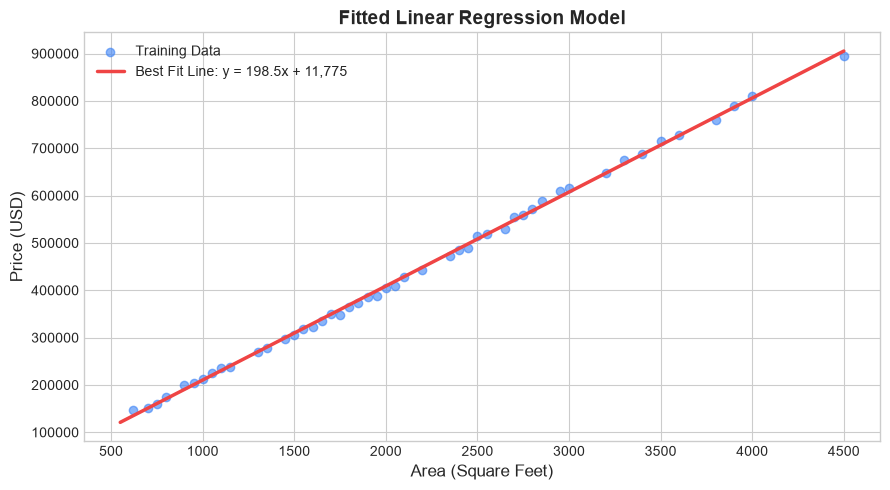

In [10]:
plt.figure(figsize=(9, 5))
plt.scatter(X_train, y_train, color='#3b82f6', label='Training Data', alpha=0.6)
line_x = np.linspace(X['area'].min(), X['area'].max(), 100).reshape(-1, 1)
line_y = model.predict(line_x)
plt.plot(line_x, line_y, color='#ef4444', linewidth=2.5, label=f'Best Fit Line: y = {slope:.1f}x + {intercept:,.0f}')
plt.title('Fitted Linear Regression Model', fontsize=14, fontweight='bold')
plt.xlabel('Area (Square Feet)', fontsize=12)
plt.ylabel('Price (USD)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

### Phase 4 — Model Evaluation
We evaluate the model on the unseen test set using standard regression metrics:
- **MAE (Mean Absolute Error)**: Average dollar error per prediction.
- **MSE (Mean Squared Error)**: Penalizes larger prediction errors heavily.
- **RMSE (Root Mean Squared Error)**: Square root of MSE, in the same dollar units as the target.
- **$R^2$ (Coefficient of Determination)**: Proportion of variance explained (1.0 = perfect fit).

In [11]:
# Predict on test set
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("=== Test Set Evaluation Metrics ===")
print(f"Mean Absolute Error (MAE): ${mae:,.2f}")
print(f"Mean Squared Error (MSE):  {mse:,.2f}")
print(f"Root Mean Squared (RMSE):  ${rmse:,.2f}")
print(f"R² Score:                  {r2:.4f} ({r2*100:.2f}% variance explained)")

=== Test Set Evaluation Metrics ===
Mean Absolute Error (MAE): $6,418.69
Mean Squared Error (MSE):  71,312,278.25
Root Mean Squared (RMSE):  $8,444.66
R² Score:                  0.9984 (99.84% variance explained)


In [12]:
# Comparison Table of Actual vs Predicted
results_df = pd.DataFrame({
    'Area (sqft)': X_test['area'].values,
    'Actual Price ($)': y_test.values,
    'Predicted Price ($)': np.round(y_pred, 2),
    'Absolute Error ($)': np.round(np.abs(y_test.values - y_pred), 2)
})
results_df.head(10)

,Area (sqft),Actual Price ($),Predicted Price ($),Absolute Error ($)
0,550,135000,120974.33,14025.67
1,850,185000,180537.64,4462.36
2,2900,585000,587553.59,2553.59
3,2150,425000,438645.32,13645.32
4,1250,262000,259955.39,2044.61
5,3700,752000,746389.09,5610.91
6,2300,450000,468426.97,18426.97
7,3100,635000,627262.47,7737.53
8,1200,250000,250028.17,28.17
9,2600,532000,527990.28,4009.72


#### Understanding Overfitting vs. Underfitting
- **Underfitting**: If the model was too simple (e.g. constant prediction), it would fail on both training and test data (low $R^2$ on both).
- **Overfitting**: If a high-degree polynomial model memorized every training noise point, training error would be near zero, but test error would explode.
- **Good Generalization**: Here our Linear Regression achieves an $R^2 > 0.95$ on unseen test data, proving excellent generalizability without overfitting!

### Phase 5 — Model Persistence with Joblib
We save the trained Scikit-Learn model to disk so our FastAPI backend can load and serve it without needing to retrain.

In [13]:
models_dir = Path('../models')
models_dir.mkdir(parents=True, exist_ok=True)
model_save_path = models_dir / 'house_price_model.pkl'

# Save model
joblib.dump(model, model_save_path)
print(f"Model successfully saved to: {model_save_path.resolve()}")

Model successfully saved to: C:\Users\basant\Documents\Basant\pythonAi\ai-model\ml-training\models\house_price_model.pkl


In [14]:
# Independent Reload Verification Test
loaded_model = joblib.load(model_save_path)
print("Model loaded from disk independently!")

# Test sample predictions for real estate inquiry
sample_areas = [1200, 1850, 2400, 3500]
print("\n--- Sample Predictions from Loaded Model ---")
for area in sample_areas:
    prediction = loaded_model.predict([[area]])[0]
    print(f"Area: {area:,} sqft  ==>  Estimated Price: ${prediction:,.2f}")

Model loaded from disk independently!

--- Sample Predictions from Loaded Model ---
Area: 1,200 sqft  ==>  Estimated Price: $250,028.17
Area: 1,850 sqft  ==>  Estimated Price: $379,082.01
Area: 2,400 sqft  ==>  Estimated Price: $488,281.41
Area: 3,500 sqft  ==>  Estimated Price: $706,680.21


C:\Users\basant\Documents\Basant\pythonAi\ai-model\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
C:\Users\basant\Documents\Basant\pythonAi\ai-model\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
C:\Users\basant\Documents\Basant\pythonAi\ai-model\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
C:\Users\basant\Documents\Basant\pythonAi\ai-model\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
